# 02.01. IPCA — Análise por Grupos

## Variação • Peso • Contribuição • Decomposição da Inflação

Este notebook inicia a decomposição do IPCA geral em seus grandes grupos
de consumo.

Ele deve ser executado após:

```text
00.auditoria_dados.ipynb
01.selic.ipynb
02.ipca.ipynb
```

O fluxo conceitual é:

```text
IPCA geral
     |
     v
  grupos
     |
     v
subgrupos
     |
     v
   itens
     |
     v
 subitens
```

O notebook assume que:

- os pipelines já foram executados;
- a tabela `bcb.ipca_grupos` está atualizada;
- a auditoria dos dados foi concluída;
- os dados estão aptos para análise.

Este notebook NÃO executa pipelines e NÃO altera o banco de dados.

---



### Objetivos

1. Entender o papel dos grupos na estrutura do IPCA.
2. Examinar a cobertura histórica dos grupos.
3. Analisar a evolução dos pesos.
4. Comparar a inflação entre grupos.
5. Calcular a contribuição aproximada de cada grupo.
6. Identificar quais grupos pressionam ou aliviam o IPCA agregado.
7. Relacionar os grupos ao IPCA geral.
8. Preparar uma representação analítica para etapas posteriores.

### 1. Estrutura hierárquica do IPCA

A estrutura utilizada pelo projeto é:

```text
grupo      -> código de 1 dígito
subgrupo   -> código de 2 dígitos
item       -> código de 4 dígitos
subitem    -> código de 7 dígitos
```

Exemplos conceituais:

```text
1       Alimentação e bebidas
11      Alimentação no domicílio
1101    Cereais, leguminosas e oleaginosas
1101002 Arroz
```

Neste notebook trabalharemos exclusivamente com o primeiro nível: ```**grupos**```

### 2. O que representam os grupos?

Os grupos são grandes categorias de consumo utilizadas na estrutura do
IPCA.

Exemplos incluem:

- Alimentação e bebidas;
- Habitação;
- Artigos de residência;
- Vestuário;
- Transportes;
- Saúde e cuidados pessoais;
- Despesas pessoais;
- Educação;
- Comunicação.

A análise por grupos permite começar a responder:

> Quais grandes componentes estão pressionando a inflação?

Isso representa um passo além do IPCA geral.

* IPCA geral $\to\qquad$ Quanto foi a inflação?
* IPCA por grupos $\to\qquad$ De onde veio a inflação?


### 3. Três conceitos fundamentais

Para interpretar corretamente os grupos precisamos distinguir:

```text
índice
peso
contribuição
```

#### 3.1 Variação mensal

A coluna:

```text
indice
```

representa a variação mensal dos preços daquele grupo.

Exemplo:

```text
Grupo A -> 1,50%
Grupo B -> 0,40%
```

Isso significa que os preços do Grupo A cresceram mais naquele mês.

Mas isso não significa necessariamente que o Grupo A tenha produzido
maior impacto sobre o IPCA geral.

#### 3.2 Peso

A coluna:

```text
peso
```

representa a importância relativa do grupo na estrutura do índice.

Um grupo com peso maior exerce, para uma mesma variação de preços, impacto
maior sobre o IPCA agregado.

#### 3.3 Contribuição

Podemos construir uma aproximação da contribuição mensal:

$$Contribuição_{i,t}=
Índice_{i,t}
\times
\frac{Peso_{i,t}}{100}
$$

onde:

- $i$ representa o grupo;
- $t$ representa o mês.

Exemplo:

| Grupo | Variação | Peso | Contribuição |
|---|---|---|---|
| A | 5,00% | 2% | 0,10 p.p. |
| B | 1,00% | 25% | 0,25 p.p. |

Apesar de o Grupo A apresentar inflação maior, o Grupo B possui maior
contribuição para o índice agregado.

Portanto:

* indice $\to\qquad$ quanto os preços variaram
* peso $\to\qquad$ quanto o grupo importa
* contribuição $\to\qquad$ quanto aproximadamente pressionou o IPCA


### 4. Configuração do ambiente

In [119]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /home/moacir/projects/ml/analytics/inflation


### 5. Importações

In [120]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.database.connection import engine

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:.4f}".format)

### 6. Carregar dados do PostgreSQL

A tabela utilizada é: ```**bcb.ipca_grupos**```

O notebook apenas consome os dados já persistidos.

In [121]:
grupos = pd.read_sql(
    """
    SELECT
        date,
        categoria,
        categoria_nome,
        indice,
        peso
    FROM bcb.ipca_grupos
    ORDER BY date, categoria;
    """,
    engine,
)

#### 6.1 Padronizar datas e ordenação

In [122]:
grupos["date"] = pd.to_datetime(grupos["date"])
grupos["categoria"] = (grupos["categoria"].astype(str))
grupos = (
    grupos
        .sort_values(
            ["date", "categoria"]
        )
        .reset_index(drop=True)
)

grupos.head(10)

,date,categoria,categoria_nome,indice,peso
0,2020-01-01,1,Alimentação e bebidas,0.3900,19.3483
1,2020-01-01,2,Habitação,0.5500,15.5945
2,2020-01-01,3,Artigos de residência,-0.0700,3.7529
3,2020-01-01,4,Vestuário,-0.4800,4.5770
4,2020-01-01,5,Transportes,0.3200,20.5979
5,2020-01-01,6,Saúde e cuidados pessoais,-0.3200,13.5334
6,2020-01-01,7,Despesas pessoais,0.3500,10.7330
7,2020-01-01,8,Educação,0.1600,6.1485
8,2020-01-01,9,Comunicação,0.1200,5.7146
9,2020-02-01,1,Alimentação e bebidas,0.1100,19.3816


### 7. Cobertura histórica

In [123]:
resumo_grupos = pd.DataFrame(
    [
        {
            "inicio": grupos["date"].min(),
            "fim": grupos["date"].max(),
            "observacoes": len(grupos),
            "categorias": grupos["categoria"].nunique(),
        }
    ]
)

resumo_grupos

,inicio,fim,observacoes,categorias
0,2020-01-01,2026-08-01,720,9


### 8. Grupos disponíveis

In [124]:
categorias = (
    grupos[
        [
            "categoria",
            "categoria_nome",
        ]
    ]
        .drop_duplicates()
        .sort_values("categoria")
        .reset_index(drop=True)
)

categorias

,categoria,categoria_nome
0,1,Alimentação e bebidas
1,2,Habitação
2,3,Artigos de residência
3,4,Vestuário
4,5,Transportes
5,6,Saúde e cuidados pessoais
6,7,Despesas pessoais
7,8,Educação
8,9,Comunicação


### 9. Quantidade de grupos ao longo do tempo

Mudanças metodológicas poderiam alterar a estrutura presente na base.

Por isso examinamos a quantidade de grupos disponível em cada mês.

In [125]:
quantidade_grupos = (
    grupos
    .groupby("date")["categoria"]
    .nunique()
    .rename("numero_grupos")
    .reset_index()
)

quantidade_grupos["numero_grupos"].describe()

count   80.0000
mean     9.0000
std      0.0000
min      9.0000
25%      9.0000
50%      9.0000
75%      9.0000
max      9.0000
Name: numero_grupos, dtype: float64

In [126]:
quantidade_grupos[
    quantidade_grupos["numero_grupos"]
    != quantidade_grupos["numero_grupos"].mode().iloc[0]
]

,date,numero_grupos


---

 PARTE I — ESTRUTURA ATUAL DO IPCA



### 10. Último mês disponível

In [127]:
ultimo_mes = grupos["date"].max()

grupos_ultimo = (
    grupos[
        grupos["date"] == ultimo_mes
    ]
    .copy()
)

print(
    "Último mês disponível:",
    ultimo_mes.strftime("%Y-%m"),
)

grupos_ultimo[
    [
        "categoria",
        "categoria_nome",
        "indice",
        "peso",
    ]
].sort_values("categoria")

Último mês disponível: 2026-08


,categoria,categoria_nome,indice,peso
711,1,Alimentação e bebidas,-0.3400,21.5115
712,2,Habitação,-1.8700,15.5030
713,3,Artigos de residência,0.6400,3.4510
714,4,Vestuário,0.1200,4.5963
715,5,Transportes,-0.8600,20.2696
716,6,Saúde e cuidados pessoais,0.2300,13.7648
717,7,Despesas pessoais,1.3000,10.2426
718,8,Educação,0.4700,6.1601
719,9,Comunicação,-0.0900,4.5011


### 11. Soma dos pesos no último mês

A soma dos pesos dos grupos deve representar aproximadamente a totalidade
da estrutura agregada do índice.

Pequenas diferenças podem resultar de arredondamento.

In [128]:
soma_pesos_ultimo = (
    grupos_ultimo["peso"].sum()
)

print(
    f"Soma dos pesos em {ultimo_mes:%Y-%m}: "
    f"{soma_pesos_ultimo:.4f}"
)

Soma dos pesos em 2026-08: 100.0000


### 12. Estrutura atual dos pesos

Este gráfico mostra quais grupos possuem maior importância relativa na
composição atual do IPCA.

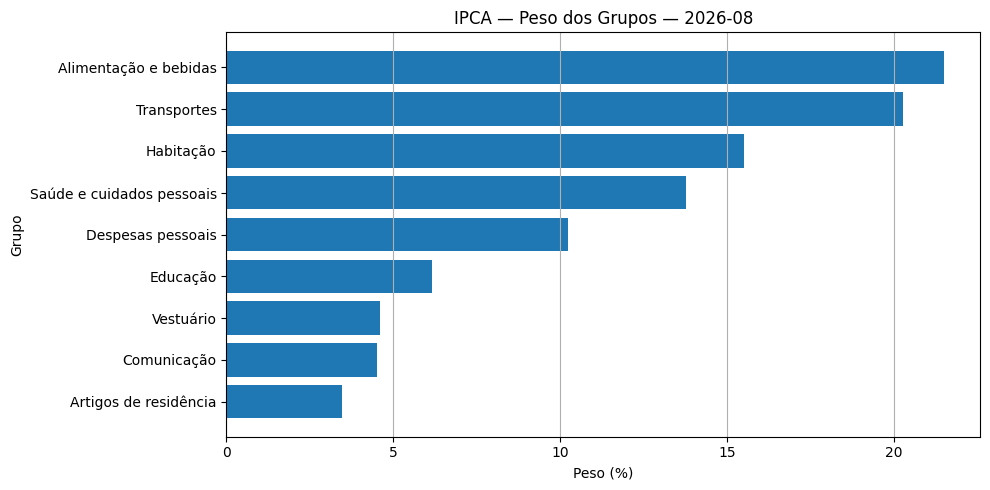

In [129]:
peso_atual = (
    grupos_ultimo
    .sort_values("peso")
)

plt.figure(figsize=(10, 5))

plt.barh(
    peso_atual["categoria_nome"],
    peso_atual["peso"],
)

plt.title(
    f"IPCA — Peso dos Grupos — {ultimo_mes:%Y-%m}"
)
plt.xlabel("Peso (%)")
plt.ylabel("Grupo")
plt.grid(True, axis="x")

plt.tight_layout()
plt.show()

### 13. Evolução dos pesos

O peso de um grupo pode mudar ao longo do tempo.

Portanto, uma média histórica do peso não representa necessariamente
sua importância atual.

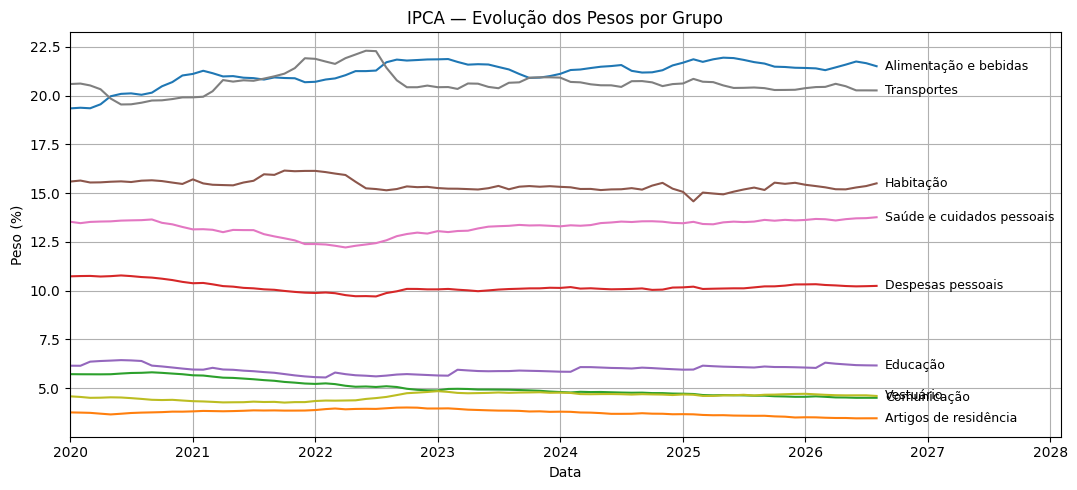

In [130]:
plt.figure(figsize=(11, 5))

for nome, grupo in grupos.groupby("categoria_nome"):
    grupo = grupo.sort_values("date")

    plt.plot(
        grupo["date"],
        grupo["peso"],
    )

    # Nome no último ponto da linha
    ultimo = grupo.iloc[-1]

    plt.annotate(
        nome,
        xy=(ultimo["date"], ultimo["peso"]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
    )

plt.title(
    "IPCA — Evolução dos Pesos por Grupo"
)
plt.xlabel("Data")
plt.ylabel("Peso (%)")
plt.grid(True)


# Espaço adicional à direita para os nomes
plt.xlim(
    grupos["date"].min(),
    grupos["date"].max() + pd.DateOffset(months=18),
)



plt.tight_layout()
plt.show()



---

## PARTE II — VARIAÇÃO MENSAL DOS GRUPOS



### 14. Janela recente de 10 anos

O histórico completo pode combinar regimes econômicos bastante distintos.

Para facilitar a leitura da dinâmica contemporânea, criamos uma janela
dos últimos 10 anos sem eliminar o histórico da base principal.

In [131]:
data_inicio_10a = (
    grupos["date"].max()
    - pd.DateOffset(years=10)
)

grupos_10a = grupos[
    grupos["date"] >= data_inicio_10a
].copy()

### 15. Variação mensal por grupo

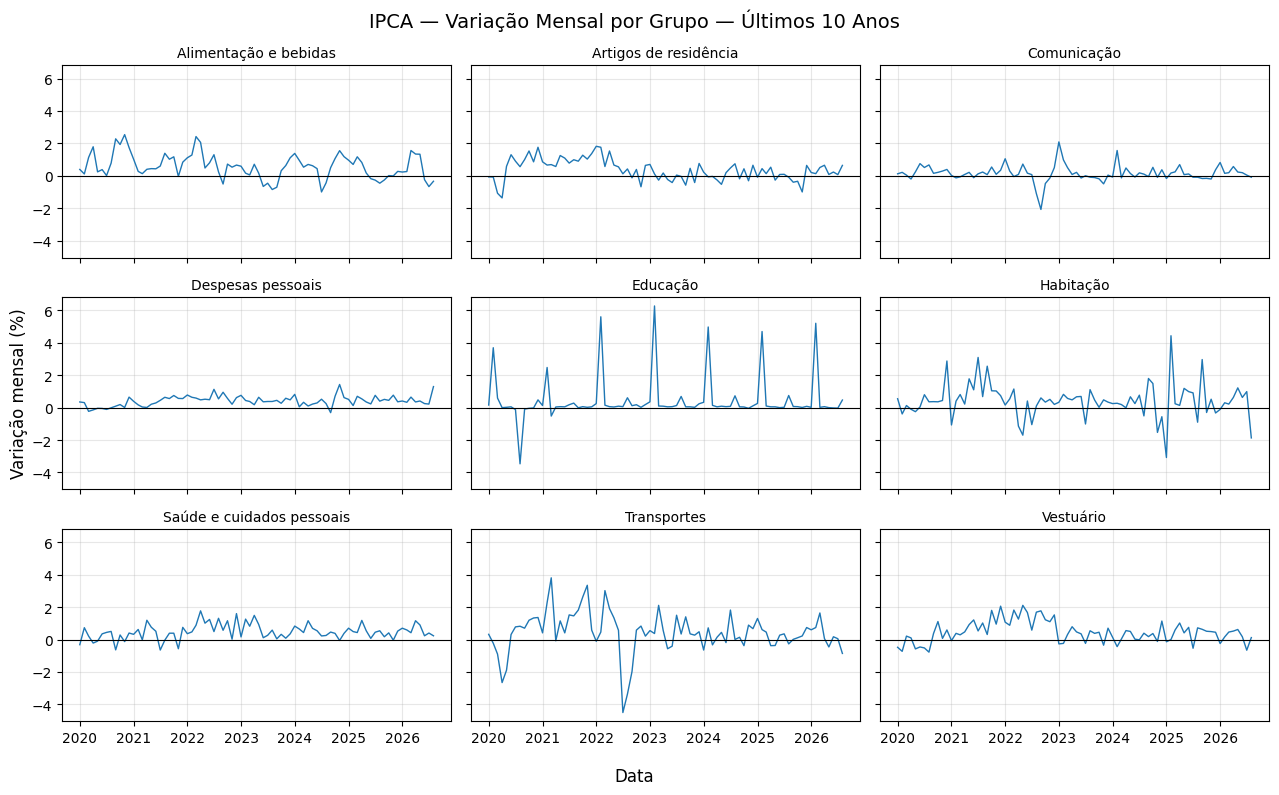

In [132]:
nomes = sorted(
    grupos_10a["categoria_nome"].unique()
)

fig, axes = plt.subplots(
    3,
    3,
    figsize=(13, 8),
    sharex=True,
    sharey=True,
)

axes = axes.flatten()

for ax, nome in zip(axes, nomes):
    grupo = grupos_10a[
        grupos_10a["categoria_nome"] == nome
    ]

    ax.plot(
        grupo["date"],
        grupo["indice"],
        linewidth=1,
    )

    ax.axhline(
        0,
        color="black",
        linewidth=0.8,
    )

    ax.set_title(
        nome,
        fontsize=10,
    )

    ax.grid(
        True,
        alpha=0.3,
    )

fig.suptitle(
    "IPCA — Variação Mensal por Grupo — Últimos 10 Anos",
    fontsize=14,
)

fig.supxlabel("Data")
fig.supylabel("Variação mensal (%)")

plt.tight_layout()
plt.show()

### 16. Heatmap dos últimos 12 meses

O heatmap permite comparar simultaneamente:

- grupos;
- meses;
- intensidade da inflação;
- ocorrência de variações negativas.

In [133]:
ultimos_12_meses = (
    grupos["date"]
    .drop_duplicates()
    .sort_values()
    .tail(12)
)

grupos_12m = grupos[
    grupos["date"].isin(
        ultimos_12_meses
    )
].copy()

grupos_12m["periodo"] = (
    grupos_12m["date"]
    .dt.strftime("%Y-%m")
)

pivot_hm = grupos_12m.pivot(
    index="categoria_nome",
    columns="periodo",
    values="indice",
)

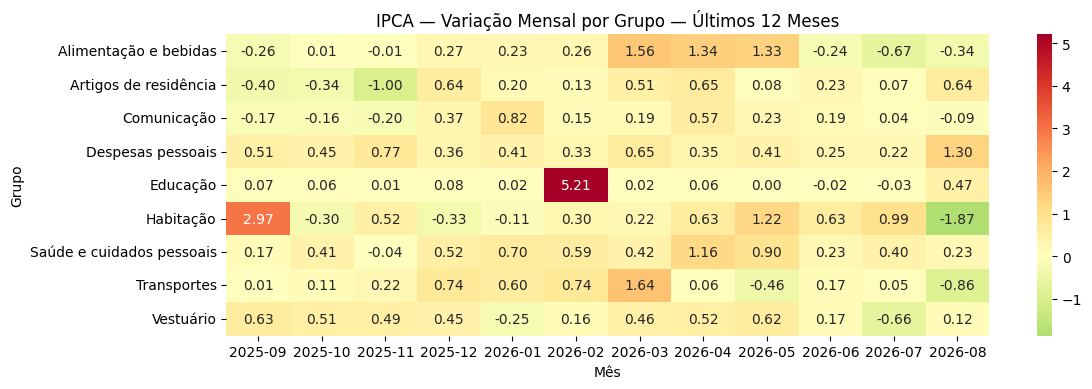

In [134]:
plt.figure(figsize=(12, 4))

sns.heatmap(
    pivot_hm,
    cmap="RdYlGn_r",
    center=0,
    annot=True,
    fmt=".2f",
)

plt.title(
    "IPCA — Variação Mensal por Grupo — Últimos 12 Meses"
)
plt.xlabel("Mês")
plt.ylabel("Grupo")

plt.tight_layout()
plt.show()

---

## PARTE III — CONTRIBUIÇÃO DOS GRUPOS



### 17. Calcular contribuição aproximada

Utilizamos:

$$
contribuição =
indice
\times
\frac{peso}{100}
$$

O resultado é expresso aproximadamente em pontos percentuais.

In [135]:
grupos["contribuicao"] = (
    grupos["indice"]
    * grupos["peso"]
    / 100
)

grupos["impacto"] = (
    grupos["contribuicao"].abs()
)

grupos[
    [
        "date",
        "categoria_nome",
        "indice",
        "peso",
        "contribuicao",
        "impacto",
    ]
].tail(18)

,date,categoria_nome,indice,peso,contribuicao,impacto
702,2026-07-01,Alimentação e bebidas,-0.6700,21.6675,-0.1452,0.1452
703,2026-07-01,Habitação,0.9900,15.3642,0.1521,0.1521
704,2026-07-01,Artigos de residência,0.0700,3.4504,0.0024,0.0024
705,2026-07-01,Vestuário,-0.6600,4.6289,-0.0306,0.0306
706,2026-07-01,Transportes,0.0500,20.2729,0.0101,0.0101
707,2026-07-01,Saúde e cuidados pessoais,0.4000,13.7181,0.0549,0.0549
708,2026-07-01,Despesas pessoais,0.2200,10.2281,0.0225,0.0225
709,2026-07-01,Educação,-0.0300,6.1673,-0.0019,0.0019
710,2026-07-01,Comunicação,0.0400,4.5026,0.0018,0.0018
711,2026-08-01,Alimentação e bebidas,-0.3400,21.5115,-0.0731,0.0731


#### 17.1 Atualizar os recortes temporais

Como `contribuicao` foi criada após os recortes anteriores, atualizamos
as visões utilizadas nas próximas análises.

In [136]:
grupos_ultimo = grupos[
    grupos["date"] == ultimo_mes
].copy()

grupos_10a = grupos[
    grupos["date"] >= data_inicio_10a
].copy()

### 18. Inflação por grupo no último mês

Esta visão responde:

> Quais grupos tiveram maior e menor variação de preços?

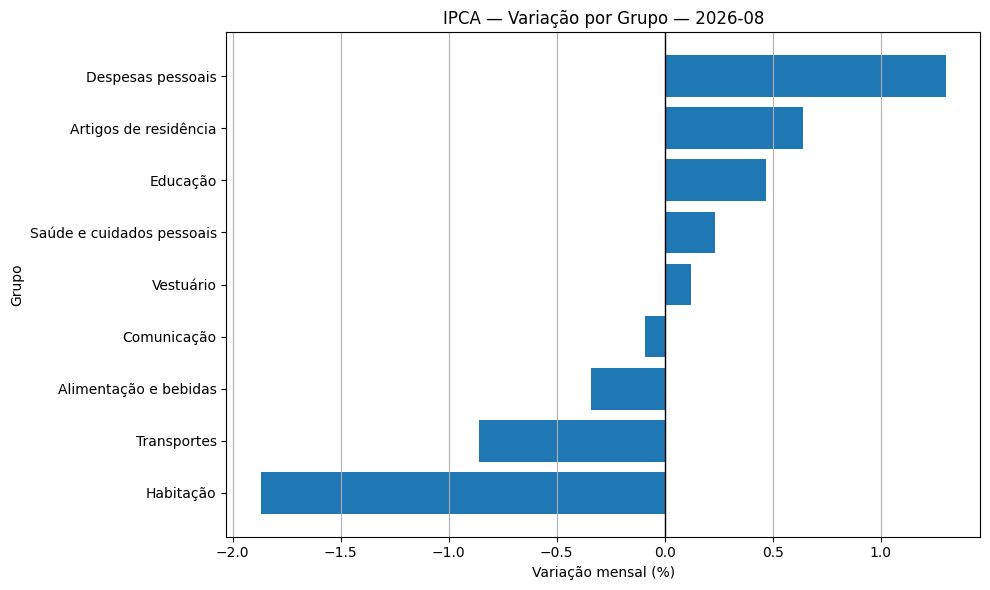

In [137]:
variacao_ultimo = (
    grupos_ultimo
    .sort_values("indice")
)

plt.figure(figsize=(10, 6))

plt.barh(
    variacao_ultimo["categoria_nome"],
    variacao_ultimo["indice"],
)

plt.axvline(
    0,
    color="black",
    linewidth=1,
)

plt.title(
    f"IPCA — Variação por Grupo — {ultimo_mes:%Y-%m}"
)
plt.xlabel("Variação mensal (%)")
plt.ylabel("Grupo")
plt.grid(True, axis="x")

plt.tight_layout()
plt.show()

### 19. Contribuição por grupo no último mês

Esta visão responde a uma pergunta diferente:

> Quais grupos mais pressionaram ou aliviaram o IPCA agregado?

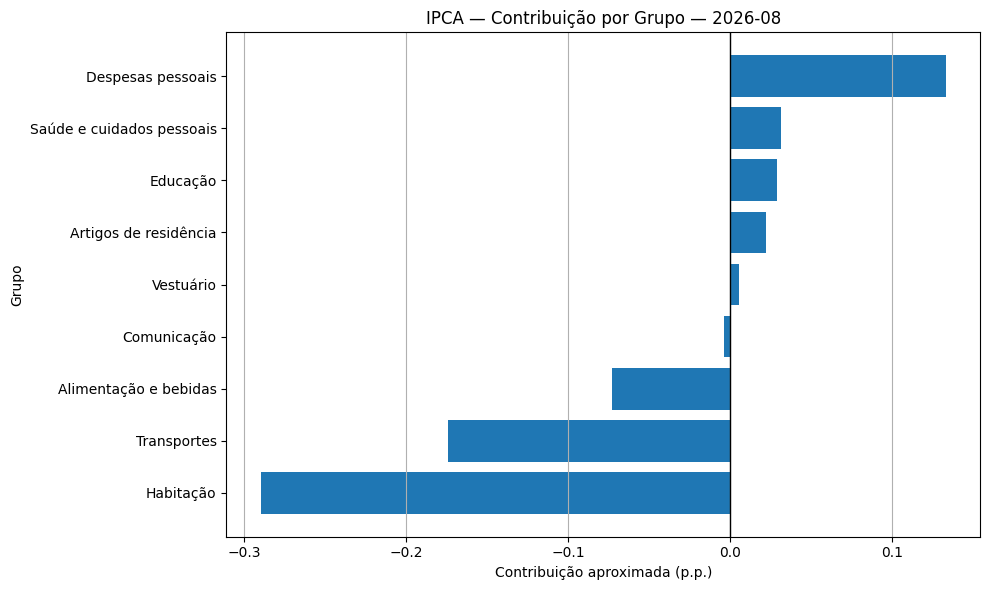

In [138]:
contribuicao_ultimo = (
    grupos_ultimo
    .sort_values("contribuicao")
)

plt.figure(figsize=(10, 6))

plt.barh(
    contribuicao_ultimo["categoria_nome"],
    contribuicao_ultimo["contribuicao"],
)

plt.axvline(
    0,
    color="black",
    linewidth=1,
)

plt.title(
    f"IPCA — Contribuição por Grupo — {ultimo_mes:%Y-%m}"
)
plt.xlabel("Contribuição aproximada (p.p.)")
plt.ylabel("Grupo")
plt.grid(True, axis="x")

plt.tight_layout()
plt.show()

### 20. Tabela do último mês

A comparação conjunta entre:

```text
indice
peso
contribuição
impacto
```

é uma das formas mais importantes de interpretar os grupos.
* tabela organizada por impacto no mês

In [139]:
resumo_ultimo_mes = (
    grupos_ultimo[
        [
            "categoria",
            "categoria_nome",
            "indice",
            "peso",
            "contribuicao",
            "impacto",
        ]
    ]
    .sort_values(
        "impacto",
        ascending=False,
    )
    .reset_index(drop=True)
)

resumo_ultimo_mes

,categoria,categoria_nome,indice,peso,contribuicao,impacto
0,2,Habitação,-1.8700,15.5030,-0.2899,0.2899
1,5,Transportes,-0.8600,20.2696,-0.1743,0.1743
2,7,Despesas pessoais,1.3000,10.2426,0.1332,0.1332
3,1,Alimentação e bebidas,-0.3400,21.5115,-0.0731,0.0731
4,6,Saúde e cuidados pessoais,0.2300,13.7648,0.0317,0.0317
5,8,Educação,0.4700,6.1601,0.0290,0.0290
6,3,Artigos de residência,0.6400,3.4510,0.0221,0.0221
7,4,Vestuário,0.1200,4.5963,0.0055,0.0055
8,9,Comunicação,-0.0900,4.5011,-0.0041,0.0041


### 21. Maiores pressões inflacionárias no último mês

In [140]:
resumo_ultimo_mes.nlargest(
    5,
    "contribuicao",
)

,categoria,categoria_nome,indice,peso,contribuicao,impacto
2,7,Despesas pessoais,1.3000,10.2426,0.1332,0.1332
4,6,Saúde e cuidados pessoais,0.2300,13.7648,0.0317,0.0317
5,8,Educação,0.4700,6.1601,0.0290,0.0290
6,3,Artigos de residência,0.6400,3.4510,0.0221,0.0221
7,4,Vestuário,0.1200,4.5963,0.0055,0.0055


### 22. Maiores contribuições negativas no último mês

In [141]:
resumo_ultimo_mes.nsmallest(
    5,
    "contribuicao",
)

,categoria,categoria_nome,indice,peso,contribuicao,impacto
0,2,Habitação,-1.8700,15.5030,-0.2899,0.2899
1,5,Transportes,-0.8600,20.2696,-0.1743,0.1743
3,1,Alimentação e bebidas,-0.3400,21.5115,-0.0731,0.0731
8,9,Comunicação,-0.0900,4.5011,-0.0041,0.0041
7,4,Vestuário,0.1200,4.5963,0.0055,0.0055


---

## PARTE IV — EVOLUÇÃO DAS CONTRIBUIÇÕES



### 23. Contribuição dos grupos ao longo do tempo

A contribuição combina:

```text
       variação do grupo
              ×
       peso do grupo
              =
   contribuição para o IPCA
```

Como as contribuições possuem sinal:

- valores positivos pressionam o IPCA para cima;
- valores negativos reduzem o IPCA no mês.

O gráfico empilhado permite observar simultaneamente:

- a direção da contribuição;
- a magnitude;
- quais grupos dominaram cada mês;
- como a composição da inflação mudou ao longo do tempo.

Para preservar a legibilidade, utilizamos os últimos 36 meses.

In [142]:
data_inicio_36m = (
    grupos["date"].max()
    - pd.DateOffset(months=35)
)

contrib_36m = (
    grupos[
        grupos["date"] >= data_inicio_36m
    ]
    .pivot(
        index="date",
        columns="categoria_nome",
        values="contribuicao",
    )
    .fillna(0)
    .sort_index()
)

# Para o gráfico de barras, usar o mês como categoria
contrib_36m.index = (
    contrib_36m.index.strftime("%Y-%m")
)

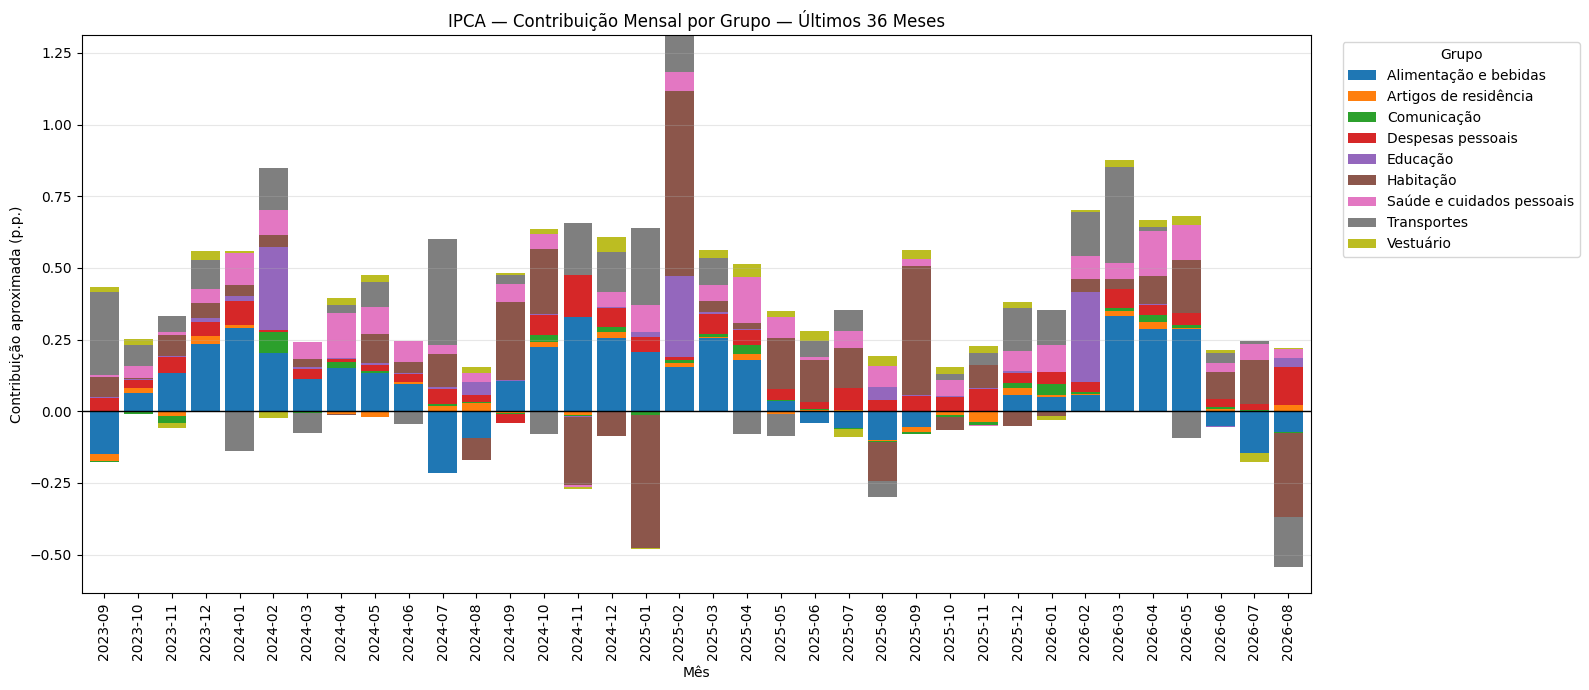

In [143]:
ax = contrib_36m.plot(
    kind="bar",
    stacked=True,
    figsize=(16, 7),
    width=0.85,
)

ax.axhline(
    0,
    color="black",
    linewidth=1,
)

ax.set_title(
    "IPCA — Contribuição Mensal por Grupo — Últimos 36 Meses"
)

ax.set_xlabel("Mês")
ax.set_ylabel("Contribuição aproximada (p.p.)")

ax.legend(
    title="Grupo",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.xticks(
    rotation=90
)

plt.grid(
    True,
    axis="y",
    alpha=0.3,
)

plt.tight_layout()
plt.show()

### 24. Matriz mensal das contribuições

Transformamos os grupos em colunas.

Essa representação será particularmente útil quando chegarmos à construção
de features.

In [144]:
contrib_pivot = (
    grupos
    .pivot(
        index="date",
        columns="categoria_nome",
        values="contribuicao",
    )
    .sort_index()
)

contrib_pivot.tail(12)

categoria_nome,Alimentação e bebidas,Artigos de residência,Comunicação,Despesas pessoais,Educação,Habitação,Saúde e cuidados pessoais,Transportes,Vestuário
date,,,,,,,,,
2025-09-01,-0.0563,-0.0143,-0.0078,0.0521,0.0043,0.4504,0.0232,0.0020,0.0293
2025-10-01,0.0021,-0.0121,-0.0073,0.0460,0.0036,-0.0466,0.0557,0.0223,0.0238
2025-11-01,-0.0021,-0.0353,-0.0091,0.0790,0.0006,0.0805,-0.0055,0.0446,0.0230
2025-12-01,0.0579,0.0223,0.0168,0.0371,0.0049,-0.0513,0.0707,0.1502,0.0212
2026-01-01,0.0493,0.0070,0.0373,0.0423,0.0012,-0.0170,0.0954,0.1223,-0.0118
2026-02-01,0.0556,0.0045,0.0069,0.0341,0.3144,0.0461,0.0807,0.1513,0.0075
2026-03-01,0.3324,0.0177,0.0086,0.0669,0.0013,0.0337,0.0574,0.3354,0.0214
2026-04-01,0.2875,0.0225,0.0258,0.0359,0.0038,0.0958,0.1577,0.0124,0.0241
2026-05-01,0.2872,0.0028,0.0104,0.0420,0.0000,0.1854,0.1230,-0.0942,0.0287


---

## PARTE V — RELAÇÃO COM O IPCA GERAL



### 25. Carregar IPCA geral

Neste ponto faz sentido trazer o agregado para comparar sua evolução com
a soma aproximada das contribuições dos grupos.

Isso NÃO substitui a auditoria feita no notebook 00.

Aqui a comparação possui objetivo analítico.

In [145]:
ipca_geral = pd.read_sql(
    """
    SELECT
        date,
        indice AS ipca_geral
    FROM bcb.ipca_geral
    ORDER BY date;
    """,
    engine,
)

ipca_geral["date"] = pd.to_datetime(
    ipca_geral["date"]
)

ipca_geral = (
    ipca_geral
    .sort_values("date")
    .reset_index(drop=True)
)

### 26. Soma mensal das contribuições

In [146]:
contrib_total = (
    grupos
    .groupby(
        "date",
        as_index=False,
    )["contribuicao"]
    .sum()
    .rename(
        columns={
            "contribuicao":
            "contribuicao_grupos"
        }
    )
)

contrib_total.tail(12)

,date,contribuicao_grupos
68,2025-09-01,0.4829
69,2025-10-01,0.0876
70,2025-11-01,0.1756
71,2025-12-01,0.3299
72,2026-01-01,0.3261
73,2026-02-01,0.7011
74,2026-03-01,0.8748
75,2026-04-01,0.6654
76,2026-05-01,0.5852
77,2026-06-01,0.1588


### 27. IPCA geral versus contribuição dos grupos

In [147]:
comparacao = (
    ipca_geral
    .merge(
        contrib_total,
        on="date",
        how="inner",
        validate="one_to_one",
    )
)

comparacao["erro"] = (
    comparacao["contribuicao_grupos"]
    - comparacao["ipca_geral"]
)

comparacao["erro_abs"] = (
    comparacao["erro"].abs()
)

comparacao.tail(12)

,date,ipca_geral,contribuicao_grupos,erro,erro_abs
68,2025-09-01,0.4800,0.4829,0.0029,0.0029
69,2025-10-01,0.0900,0.0876,-0.0024,0.0024
70,2025-11-01,0.1800,0.1756,-0.0044,0.0044
71,2025-12-01,0.3300,0.3299,-0.0001,0.0001
72,2026-01-01,0.3300,0.3261,-0.0039,0.0039
73,2026-02-01,0.7000,0.7011,0.0011,0.0011
74,2026-03-01,0.8800,0.8748,-0.0052,0.0052
75,2026-04-01,0.6700,0.6654,-0.0046,0.0046
76,2026-05-01,0.5800,0.5852,0.0052,0.0052
77,2026-06-01,0.1600,0.1588,-0.0012,0.0012


### 28. Distribuição da diferença

Pequenas diferenças podem decorrer de arredondamentos e características
metodológicas dos valores disponibilizados.

O objetivo aqui é observar a magnitude dessa diferença.

In [148]:
comparacao["erro"].describe()

count   80.0000
mean    -0.0004
std      0.0033
min     -0.0065
25%     -0.0035
50%     -0.0008
75%      0.0024
max      0.0066
Name: erro, dtype: float64

### 29. Evolução do erro

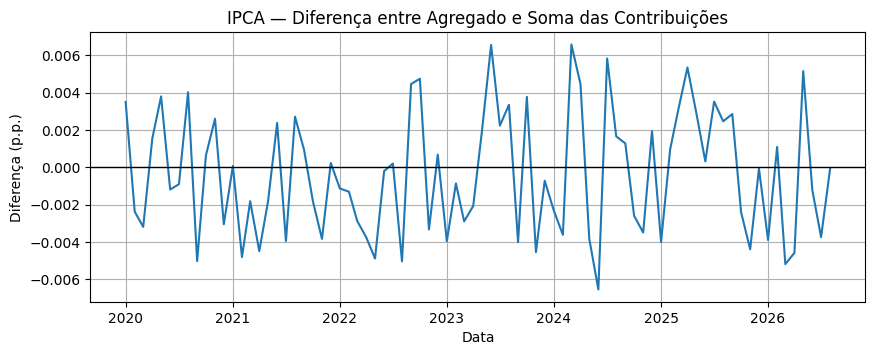

In [149]:
plt.figure(figsize=(10, 3.5))

plt.plot(
    comparacao["date"],
    comparacao["erro"],
)

plt.axhline(
    0,
    color="black",
    linewidth=1,
)

plt.title(
    "IPCA — Diferença entre Agregado e Soma das Contribuições"
)
plt.xlabel("Data")
plt.ylabel("Diferença (p.p.)")
plt.grid(True)

plt.show()

### 30. Comparação no período recente

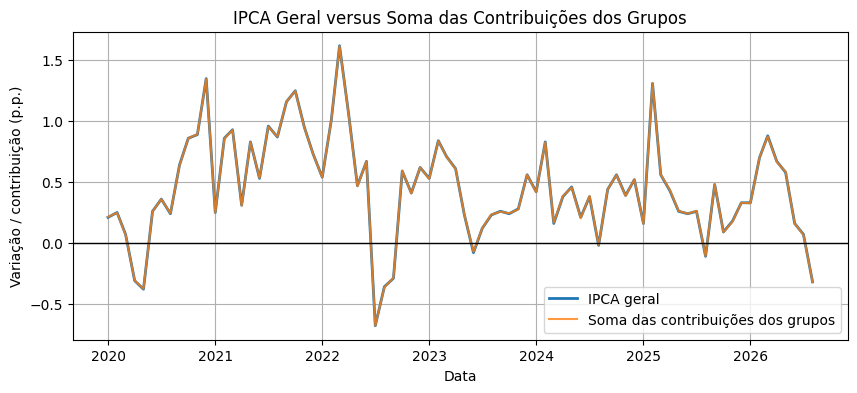

In [150]:
comparacao_10a = comparacao[
    comparacao["date"] >= data_inicio_10a
].copy()

plt.figure(figsize=(10, 4))

plt.plot(
    comparacao_10a["date"],
    comparacao_10a["ipca_geral"],
    label="IPCA geral",
    linewidth=2,
)

plt.plot(
    comparacao_10a["date"],
    comparacao_10a["contribuicao_grupos"],
    label="Soma das contribuições dos grupos",
    alpha=0.8,
)

plt.axhline(
    0,
    color="black",
    linewidth=1,
)

plt.title(
    "IPCA Geral versus Soma das Contribuições dos Grupos"
)
plt.xlabel("Data")
plt.ylabel("Variação / contribuição (p.p.)")
plt.grid(True)
plt.legend()

plt.show()

---

## PARTE VI — DINÂMICA ENTRE GRUPOS



### 31. Grupo de maior inflação por mês

Podemos identificar qual grupo apresentou a maior variação mensal em
cada período.

In [151]:
idx_maior_inflacao = (
    grupos
    .groupby("date")["indice"]
    .idxmax()
)

maior_inflacao_mes = (
    grupos.loc[
        idx_maior_inflacao,
        [
            "date",
            "categoria_nome",
            "indice",
            "peso",
            "contribuicao",
        ],
    ]
    .sort_values("date")
    .reset_index(drop=True)
)

maior_inflacao_mes.tail(12)

,date,categoria_nome,indice,peso,contribuicao
68,2025-09-01,Habitação,2.9700,15.1636,0.4504
69,2025-10-01,Vestuário,0.5100,4.6654,0.0238
70,2025-11-01,Despesas pessoais,0.7700,10.2567,0.0790
71,2025-12-01,Transportes,0.7400,20.3033,0.1502
72,2026-01-01,Comunicação,0.8200,4.5542,0.0373
73,2026-02-01,Educação,5.2100,6.0348,0.3144
74,2026-03-01,Transportes,1.6400,20.4516,0.3354
75,2026-04-01,Alimentação e bebidas,1.3400,21.4524,0.2875
76,2026-05-01,Alimentação e bebidas,1.3300,21.5939,0.2872
77,2026-06-01,Habitação,0.6300,15.2915,0.0963


### 32. Grupo de maior impacto por mês

O grupo que apresenta maior inflação não é necessariamente o grupo de
maior impacto.

In [152]:
idx_maior_contrib = (
    grupos
    .groupby("date")["impacto"]
    .idxmax()
)

maior_contrib_mes = (
    grupos.loc[
        idx_maior_contrib,
        [
            "date",
            "categoria_nome",
            "indice",
            "peso",
            "impacto",
        ],
    ]
    .sort_values("date")
    .reset_index(drop=True)
)

maior_contrib_mes.tail(12)

,date,categoria_nome,indice,peso,impacto
68,2025-09-01,Habitação,2.9700,15.1636,0.4504
69,2025-10-01,Saúde e cuidados pessoais,0.4100,13.5865,0.0557
70,2025-11-01,Habitação,0.5200,15.4783,0.0805
71,2025-12-01,Transportes,0.7400,20.3033,0.1502
72,2026-01-01,Transportes,0.6000,20.3868,0.1223
73,2026-02-01,Educação,5.2100,6.0348,0.3144
74,2026-03-01,Transportes,1.6400,20.4516,0.3354
75,2026-04-01,Alimentação e bebidas,1.3400,21.4524,0.2875
76,2026-05-01,Alimentação e bebidas,1.3300,21.5939,0.2872
77,2026-06-01,Habitação,0.6300,15.2915,0.0963


### 33. Frequência como maior contribuição

Esta tabela conta quantas vezes cada grupo foi a maior contribuição
inflacionária do mês no histórico disponível.

In [153]:
frequencia_maior_contrib = (
    maior_contrib_mes["categoria_nome"]
    .value_counts()
    .rename("meses")
    .to_frame()
)

frequencia_maior_contrib

,meses
categoria_nome,
Alimentação e bebidas,27
Transportes,22
Habitação,19
Educação,6
Saúde e cuidados pessoais,6


---

## PARTE VII — DATASET ANALÍTICO



### 34. Representação longa

O formato original é adequado para análises por categoria:

* date
* categoria
* categoria_nome
* indice
* peso
* contribuicao


In [154]:
grupos_analitico = grupos[
    [
        "date",
        "categoria",
        "categoria_nome",
        "indice",
        "peso",
        "contribuicao",
    ]
].copy()

grupos_analitico.tail(18)

,date,categoria,categoria_nome,indice,peso,contribuicao
702,2026-07-01,1,Alimentação e bebidas,-0.6700,21.6675,-0.1452
703,2026-07-01,2,Habitação,0.9900,15.3642,0.1521
704,2026-07-01,3,Artigos de residência,0.0700,3.4504,0.0024
705,2026-07-01,4,Vestuário,-0.6600,4.6289,-0.0306
706,2026-07-01,5,Transportes,0.0500,20.2729,0.0101
707,2026-07-01,6,Saúde e cuidados pessoais,0.4000,13.7181,0.0549
708,2026-07-01,7,Despesas pessoais,0.2200,10.2281,0.0225
709,2026-07-01,8,Educação,-0.0300,6.1673,-0.0019
710,2026-07-01,9,Comunicação,0.0400,4.5026,0.0018
711,2026-08-01,1,Alimentação e bebidas,-0.3400,21.5115,-0.0731


### 35. Representação larga da variação mensal

Para futura modelagem, uma possibilidade é transformar cada grupo em
uma coluna.

In [155]:
indice_pivot = (
    grupos
    .pivot(
        index="date",
        columns="categoria_nome",
        values="indice",
    )
    .sort_index()
)

indice_pivot.tail(12)

categoria_nome,Alimentação e bebidas,Artigos de residência,Comunicação,Despesas pessoais,Educação,Habitação,Saúde e cuidados pessoais,Transportes,Vestuário
date,,,,,,,,,
2025-09-01,-0.2600,-0.4000,-0.1700,0.5100,0.0700,2.9700,0.1700,0.0100,0.6300
2025-10-01,0.0100,-0.3400,-0.1600,0.4500,0.0600,-0.3000,0.4100,0.1100,0.5100
2025-11-01,-0.0100,-1.0000,-0.2000,0.7700,0.0100,0.5200,-0.0400,0.2200,0.4900
2025-12-01,0.2700,0.6400,0.3700,0.3600,0.0800,-0.3300,0.5200,0.7400,0.4500
2026-01-01,0.2300,0.2000,0.8200,0.4100,0.0200,-0.1100,0.7000,0.6000,-0.2500
2026-02-01,0.2600,0.1300,0.1500,0.3300,5.2100,0.3000,0.5900,0.7400,0.1600
2026-03-01,1.5600,0.5100,0.1900,0.6500,0.0200,0.2200,0.4200,1.6400,0.4600
2026-04-01,1.3400,0.6500,0.5700,0.3500,0.0600,0.6300,1.1600,0.0600,0.5200
2026-05-01,1.3300,0.0800,0.2300,0.4100,0.0000,1.2200,0.9000,-0.4600,0.6200


### 36. Representação larga dos pesos

In [156]:
peso_pivot = (
    grupos
    .pivot(
        index="date",
        columns="categoria_nome",
        values="peso",
    )
    .sort_index()
)

peso_pivot.tail(12)

categoria_nome,Alimentação e bebidas,Artigos de residência,Comunicação,Despesas pessoais,Educação,Habitação,Saúde e cuidados pessoais,Transportes,Vestuário
date,,,,,,,,,
2025-09-01,21.6477,3.5799,4.6107,10.2173,6.1065,15.1636,13.6288,20.3871,4.6584
2025-10-01,21.4882,3.5485,4.5808,10.2196,6.0810,15.5382,13.5865,20.2916,4.6654
2025-11-01,21.4722,3.5331,4.5697,10.2567,6.0795,15.4783,13.6303,20.2954,4.6849
2025-12-01,21.4332,3.4919,4.5529,10.3169,6.0689,15.5314,13.6015,20.3033,4.7001
2026-01-01,21.4221,3.5028,4.5542,10.3196,6.0534,15.4290,13.6259,20.3868,4.7062
2026-02-01,21.4014,3.4983,4.5768,10.3280,6.0348,15.3627,13.6769,20.4422,4.6789
2026-03-01,21.3095,3.4789,4.5518,10.2891,6.3035,15.2989,13.6621,20.4516,4.6546
2026-04-01,21.4524,3.4660,4.5210,10.2667,6.2508,15.2007,13.5984,20.6094,4.6345
2026-05-01,21.5939,3.4654,4.5171,10.2357,6.2144,15.1949,13.6659,20.4854,4.6271


### 37. Representação larga das impacto

In [157]:
contrib_pivot.tail(12)

categoria_nome,Alimentação e bebidas,Artigos de residência,Comunicação,Despesas pessoais,Educação,Habitação,Saúde e cuidados pessoais,Transportes,Vestuário
date,,,,,,,,,
2025-09-01,-0.0563,-0.0143,-0.0078,0.0521,0.0043,0.4504,0.0232,0.0020,0.0293
2025-10-01,0.0021,-0.0121,-0.0073,0.0460,0.0036,-0.0466,0.0557,0.0223,0.0238
2025-11-01,-0.0021,-0.0353,-0.0091,0.0790,0.0006,0.0805,-0.0055,0.0446,0.0230
2025-12-01,0.0579,0.0223,0.0168,0.0371,0.0049,-0.0513,0.0707,0.1502,0.0212
2026-01-01,0.0493,0.0070,0.0373,0.0423,0.0012,-0.0170,0.0954,0.1223,-0.0118
2026-02-01,0.0556,0.0045,0.0069,0.0341,0.3144,0.0461,0.0807,0.1513,0.0075
2026-03-01,0.3324,0.0177,0.0086,0.0669,0.0013,0.0337,0.0574,0.3354,0.0214
2026-04-01,0.2875,0.0225,0.0258,0.0359,0.0038,0.0958,0.1577,0.0124,0.0241
2026-05-01,0.2872,0.0028,0.0104,0.0420,0.0000,0.1854,0.1230,-0.0942,0.0287


### 38. Implicações para futura modelagem

Os grupos criam novas possibilidades de features.

Um vetor de informações em determinado mês poderia conter: 
$X_t = [Alimentação_t, Habitação_t, Transportes_t, Saúde_t, \ldots]$

ou suas contribuições:
$X_t = [ContribAlimentação_t, ContribHabitação_t, ContribTransportes_t, \ldots]$

Posteriormente também poderemos trabalhar com defasagens:
$X_t = [Grupo1_{t-1}, Grupo1_{t-2}, Grupo2_{t-1}, \ldots]$

Contudo, ainda NÃO estamos criando o dataset final de machine learning.

#### 38.1 Cuidados futuros

A inclusão dos grupos em modelos exigirá atenção a:

* **Multicolinearidade**  
Os grupos participam da construção do próprio IPCA agregado.  
Portanto, várias features podem carregar informações correlacionadas.

* Leakage temporal  
Para prever o IPCA de um mês futuro, só poderemos utilizar informações  
disponíveis no momento da previsão.

* Disponibilidade da informação  
Um valor publicado juntamente com o target não pode ser usado como feature  
para prever aquele mesmo target em uma aplicação real de forecasting.

* Mudanças estruturais  
Pesos e relações entre categorias podem mudar ao longo do tempo.

* Dimensionalidade  
A quantidade de variáveis crescerá significativamente quando avançarmos  
para:
    - subgrupos
    - itens
    - subitens


Esse ponto será importante para métodos de regularização e seleção de
features.

---

### 39. Conclusões

Este notebook iniciou a decomposição da inflação agregada.

#### Variação
A variação mensal responde:
> Quais grupos tiveram os maiores movimentos de preços?

#### Peso
O peso responde:
> Qual é a importância relativa de cada grupo na estrutura do IPCA?

#### Contribuição
A contribuição combina as duas dimensões: $contribuição= variação \times peso$

e responde:
> Quais grupos efetivamente exerceram maior pressão sobre o IPCA?




#### Progressão analítica

Neste ponto temos:

```text
02.ipca
    |
    v
inflação agregada
    |
    v
02.01.grupos
    |
    v
decomposição em grandes componentes
```

O próximo nível hierárquico permitirá decompor cada grupo:

```text
grupo
  |
  v
subgrupo
  |
  v
item
  |
  v
subitem
```

Essa progressão permitirá distinguir:

```text
quanto foi a inflação
         |
         v
quais grupos explicaram
         |
         v
quais componentes internos explicaram os grupos
```

Posteriormente essa estrutura será integrada às variáveis macroeconômicas
e à SELIC para construção dos datasets de modelagem.